# Nolan's actor–film network

In [ ]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
from IPython.display import Markdown, display

%matplotlib inline

PROJECT = Path.cwd()
if not (PROJECT / "data/nolan/graphs/nolan_bipartite.graphml").is_file():
    PROJECT = PROJECT / "Final project"
GRAPH_FILE = PROJECT / "data/nolan/graphs/nolan_bipartite.graphml"
if not GRAPH_FILE.is_file():
    raise FileNotFoundError("Open this notebook from the repository root or Final project folder.")

FIGURES = PROJECT / "figures"
FIGURES.mkdir(exist_ok=True)

## Load the graph


In [11]:
G = nx.read_graphml(GRAPH_FILE)
actors = sorted(n for n, d in G.nodes(data=True) if d["node_type"] == "actor")
films = sorted(
    (n for n, d in G.nodes(data=True) if d["node_type"] == "film"),
    key=lambda n: (G.nodes[n]["year"], G.nodes[n]["label"]),
)

assert nx.is_bipartite(G)
assert len(actors) + len(films) == len(G)
assert all(G.nodes[a]["node_type"] != G.nodes[b]["node_type"] for a, b in G.edges())

print(f"Films: {len(films):,}")
print(f"Actors: {len(actors):,}")
print(f"Nodes: {G.number_of_nodes():,}")
print(f"Casting links: {G.number_of_edges():,}")
print(f"Connected components: {nx.number_connected_components(G)}")
print(f"Actors in at least two Nolan films: {sum(G.degree(a) >= 2 for a in actors)}")

Films: 13
Actors: 788
Nodes: 801
Casting links: 878
Connected components: 1
Actors in at least two Nolan films: 58


## Draw the full network



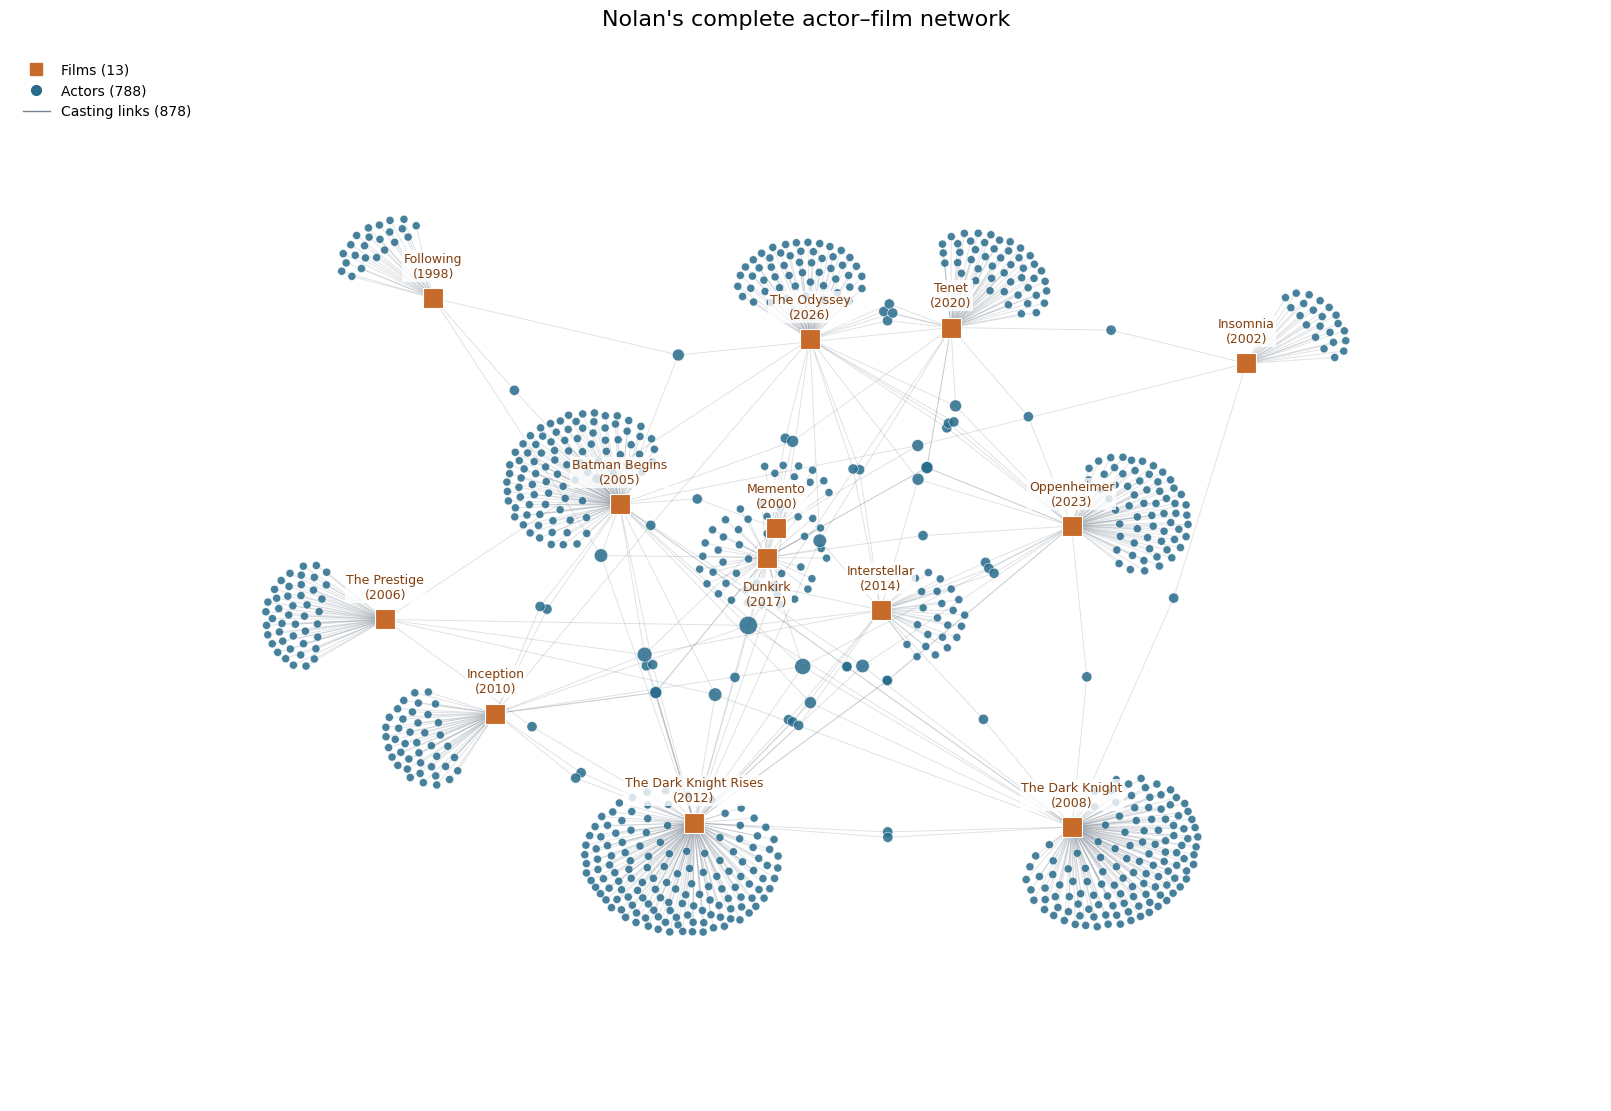

In [3]:
FILM_COLOR = "#c76b2a"
ACTOR_COLOR = "#286b8b"


def draw_cast_network(graph, title, filename, actor_label_count=0, seed=41):
    film_nodes = [n for n in films if n in graph]
    actor_nodes = [n for n in actors if n in graph]
    ordered = nx.Graph()
    ordered.add_nodes_from(sorted(graph))
    ordered.add_edges_from(graph.edges())
    pos = nx.spring_layout(ordered, seed=seed, iterations=220, weight=None)
    fig, ax = plt.subplots(figsize=(16, 11), layout="constrained")

    nx.draw_networkx_edges(graph, pos, ax=ax, edge_color="#7a8591", alpha=0.25, width=0.65)
    nx.draw_networkx_nodes(
        graph, pos, nodelist=actor_nodes, ax=ax,
        node_color=ACTOR_COLOR, node_shape="o",
        node_size=[14 + 20 * graph.degree(n) for n in actor_nodes],
        edgecolors="white", linewidths=0.4, alpha=0.85,
    )
    nx.draw_networkx_nodes(
        graph, pos, nodelist=film_nodes, ax=ax,
        node_color=FILM_COLOR, node_shape="s", node_size=190,
        edgecolors="white", linewidths=0.8,
    )

    # A small offset keeps labels clear of the node markers.
    for node in film_nodes:
        label = textwrap.fill(graph.nodes[node]["label"], width=22)
        label += f"\n({graph.nodes[node]['year']})"
        ax.annotate(
            label, xy=pos[node], xytext=(0, 13), textcoords="offset points",
            ha="center", va="bottom", fontsize=9, color="#823e0c",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.2),
        )

    labelled_actors = sorted(
        actor_nodes, key=lambda n: (-graph.degree(n), graph.nodes[n]["label"])
    )[:actor_label_count]
    for node in labelled_actors:
        ax.annotate(
            graph.nodes[node]["label"], xy=pos[node], xytext=(5, -10),
            textcoords="offset points", ha="left", va="top", fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1),
        )

    legend = [
        Line2D([], [], marker="s", linestyle="none", color=FILM_COLOR,
               markersize=9, label=f"Films ({len(film_nodes)})"),
        Line2D([], [], marker="o", linestyle="none", color=ACTOR_COLOR,
               markersize=7, label=f"Actors ({len(actor_nodes)})"),
        Line2D([], [], color="#7a8591", linewidth=1,
               label=f"Casting links ({graph.number_of_edges()})"),
    ]
    ax.legend(handles=legend, loc="upper left", frameon=False)
    ax.set_title(title, fontsize=16, pad=18)
    ax.margins(0.17)
    ax.set_axis_off()
    # Move a label to a nearby position if it overlaps an earlier label.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    occupied = []
    for label in ax.texts:
        choices = [
            (*label.get_position(), label.get_ha(), label.get_va()),
            (0, 14, "center", "bottom"), (0, -16, "center", "top"),
            (12, 0, "left", "center"), (-12, 0, "right", "center"),
            (8, 26, "left", "bottom"), (8, -28, "left", "top"),
            (-8, 26, "right", "bottom"), (-8, -28, "right", "top"),
        ]
        for x, y, horizontal, vertical in choices:
            label.set_position((x, y))
            label.set_ha(horizontal)
            label.set_va(vertical)
            bounds = label.get_window_extent(renderer).expanded(1.05, 1.15)
            if not any(bounds.overlaps(other) for other in occupied):
                break
        occupied.append(bounds)

    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()


draw_cast_network(G, "Nolan's complete actor–film network", "nolan_full_network.png")

## Recurring actors

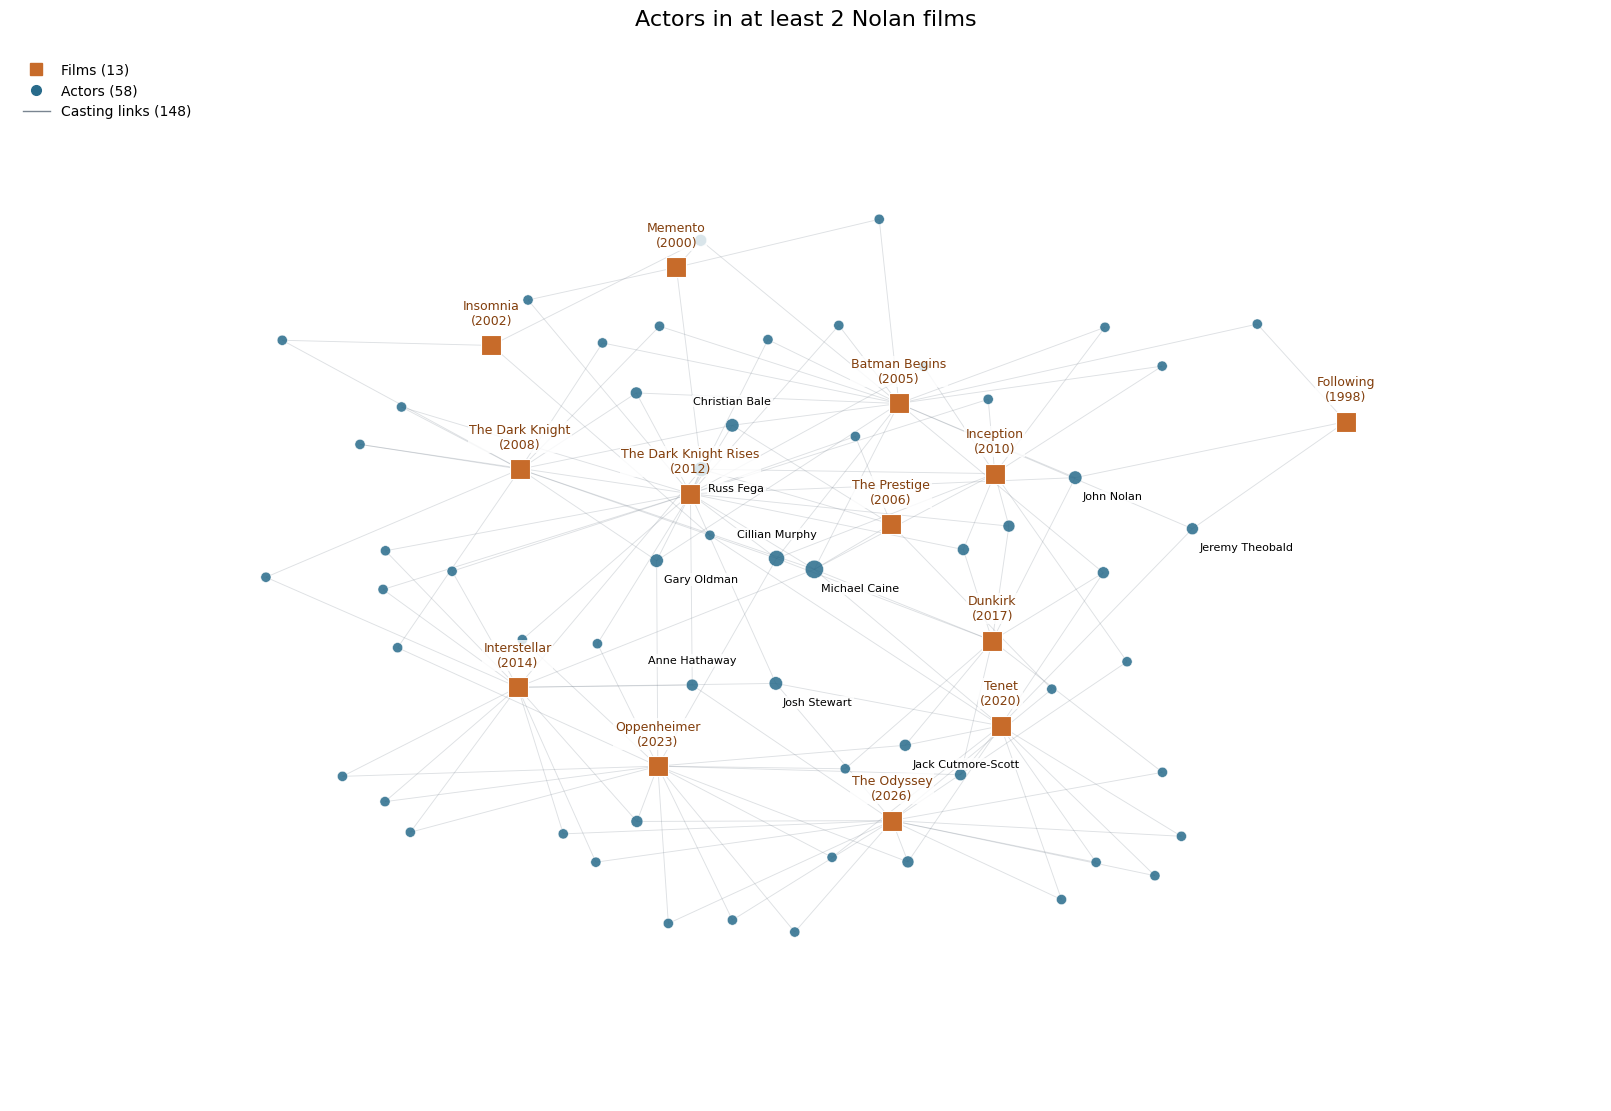

In [4]:
minimum_appearances = 2
recurring_actors = [a for a in actors if G.degree(a) >= minimum_appearances]
recurring = G.subgraph(films + recurring_actors).copy()

draw_cast_network(
    recurring,
    f"Actors in at least {minimum_appearances} Nolan films",
    "nolan_recurring_actors.png",
    actor_label_count=10,
)

In [5]:
leaders = sorted(actors, key=lambda a: (-G.degree(a), G.nodes[a]["label"]))[:15]
rows = ["| Actor | Nolan films |", "| :--- | ---: |"]
rows += [f"| {G.nodes[a]['label']} | {G.degree(a)} |" for a in leaders]
display(Markdown("\n".join(rows)))

| Actor | Nolan films |
| :--- | ---: |
| Michael Caine | 8 |
| Cillian Murphy | 6 |
| Russ Fega | 5 |
| Christian Bale | 4 |
| Gary Oldman | 4 |
| John Nolan | 4 |
| Josh Stewart | 4 |
| Anne Hathaway | 3 |
| Jack Cutmore-Scott | 3 |
| Jeremy Theobald | 3 |
| Kenneth Branagh | 3 |
| Larry Holden | 3 |
| Matt Damon | 3 |
| Miranda Nolan | 3 |
| Morgan Freeman | 3 |

In [14]:
from collections import Counter

actor_appearances = {actor: G.degree(actor) for actor in actors}
appearance_distribution = Counter(actor_appearances.values())
film_cast_sizes = {film: G.degree(film) for film in films}

assert sum(appearance_distribution.values()) == len(actors)
assert sum(actor_appearances.values()) == G.number_of_edges()
assert sum(film_cast_sizes.values()) == G.number_of_edges()

single_film_actors = appearance_distribution[1]
multiple_film_actors = sum(count for appearances, count in appearance_distribution.items()
                           if appearances >= 2)
largest_cast = max(films, key=lambda film: film_cast_sizes[film])
smallest_cast = min(films, key=lambda film: film_cast_sizes[film])

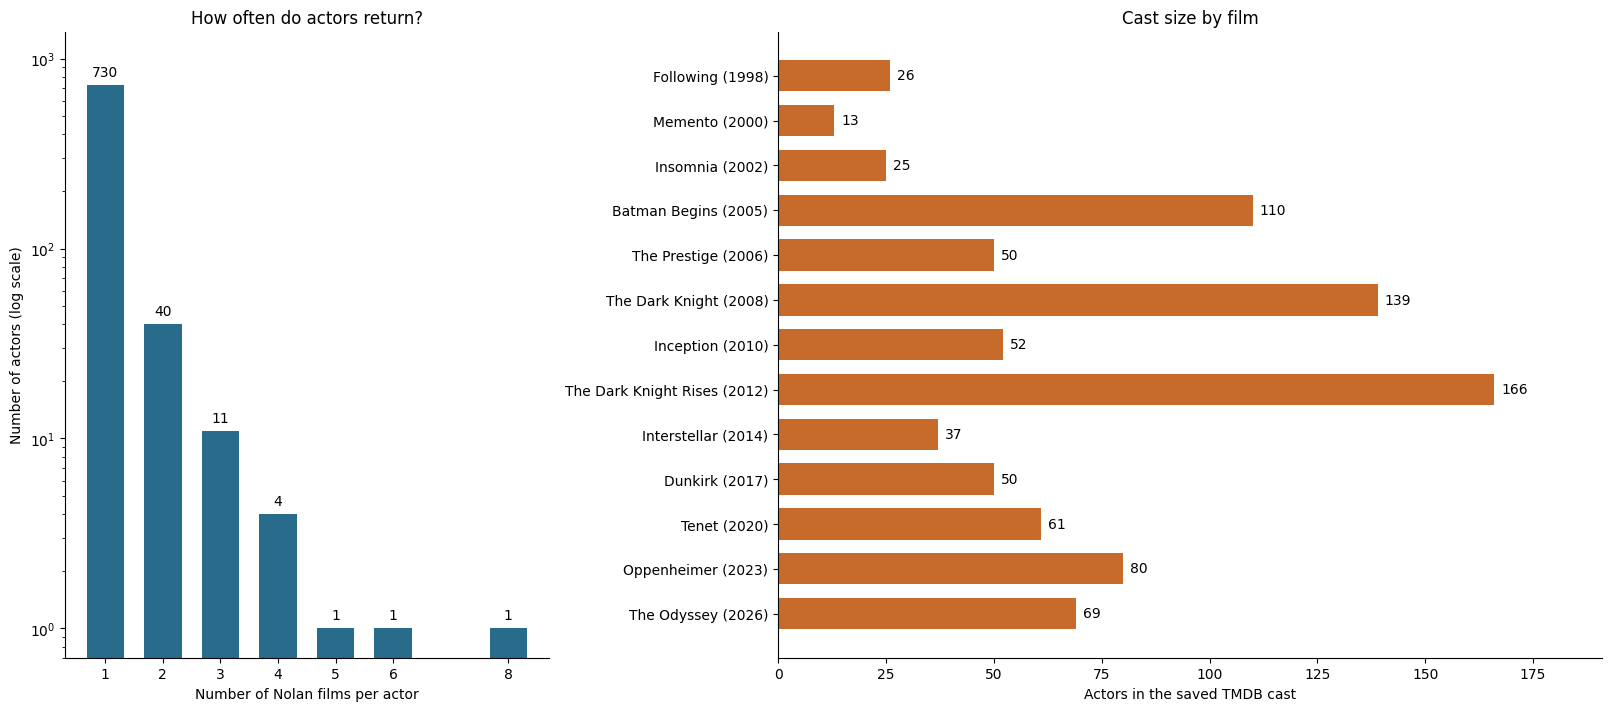

In [7]:
fig, axes = plt.subplots(
    1, 2, figsize=(16, 7), layout="constrained", gridspec_kw={"width_ratios": [1, 1.7]}
)

observed_counts = sorted(appearance_distribution)
actor_bars = axes[0].bar(
    observed_counts, [appearance_distribution[k] for k in observed_counts],
    color=ACTOR_COLOR, width=0.65,
)
axes[0].set_yscale("log")
axes[0].set_ylim(0.7, max(appearance_distribution.values()) * 1.9)
axes[0].set_xticks(observed_counts)
axes[0].bar_label(actor_bars, padding=4)
axes[0].set(title="How often do actors return?",
            xlabel="Number of Nolan films per actor",
            ylabel="Number of actors (log scale)")

film_labels = [textwrap.fill(G.nodes[film]["label"], width=25)
               + f" ({G.nodes[film]['year']})" for film in films]
cast_bars = axes[1].barh(film_labels, [film_cast_sizes[film] for film in films],
                        color=FILM_COLOR, height=0.7)
axes[1].bar_label(cast_bars, padding=5)
axes[1].invert_yaxis()
axes[1].set_xlim(0, max(film_cast_sizes.values()) * 1.15)
axes[1].set(title="Cast size by film", xlabel="Actors in the saved TMDB cast")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIGURES / "nolan_casting_patterns.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

### Which actors connect the films?

**Betweenness centrality** measures how often a node lies on shortest paths
between other nodes. When several equally short paths exist, each receives a
fraction of the credit. We compute exact betweenness on the full, unweighted
actor–film graph, then rank the actor nodes.

In [8]:
betweenness = nx.betweenness_centrality(
    G, normalized=True, weight=None, endpoints=False
)
assert all(0 <= value <= 1 for value in betweenness.values())
assert all(betweenness[actor] == 0 for actor in actors if actor_appearances[actor] == 1)

top_connectors = sorted(
    actors, key=lambda actor: (-betweenness[actor], G.nodes[actor]["label"])
)[:10]
table = ["| Actor | Nolan films | Betweenness |",
         "| :--- | ---: | ---: |"]
table += [f"| {G.nodes[actor]['label']} | {actor_appearances[actor]} | {betweenness[actor]:.4f} |"
          for actor in top_connectors]
display(Markdown("\n".join(table)))

print(f"Actors with positive betweenness: {sum(betweenness[a] > 0 for a in actors)} / {len(actors)}")
top_actor = top_connectors[0]
print(f"Highest actor betweenness: {G.nodes[top_actor]['label']} ({betweenness[top_actor]:.4f})")

| Actor | Nolan films | Betweenness |
| :--- | ---: | ---: |
| Michael Caine | 8 | 0.2030 |
| Cillian Murphy | 6 | 0.1146 |
| Gary Oldman | 4 | 0.0630 |
| Christian Bale | 4 | 0.0532 |
| John Nolan | 4 | 0.0495 |
| Josh Stewart | 4 | 0.0455 |
| Russ Fega | 5 | 0.0350 |
| Larry Holden | 3 | 0.0261 |
| Morgan Freeman | 3 | 0.0253 |
| Jeremy Theobald | 3 | 0.0251 |

Actors with positive betweenness: 58 / 788
Highest actor betweenness: Michael Caine (0.2030)


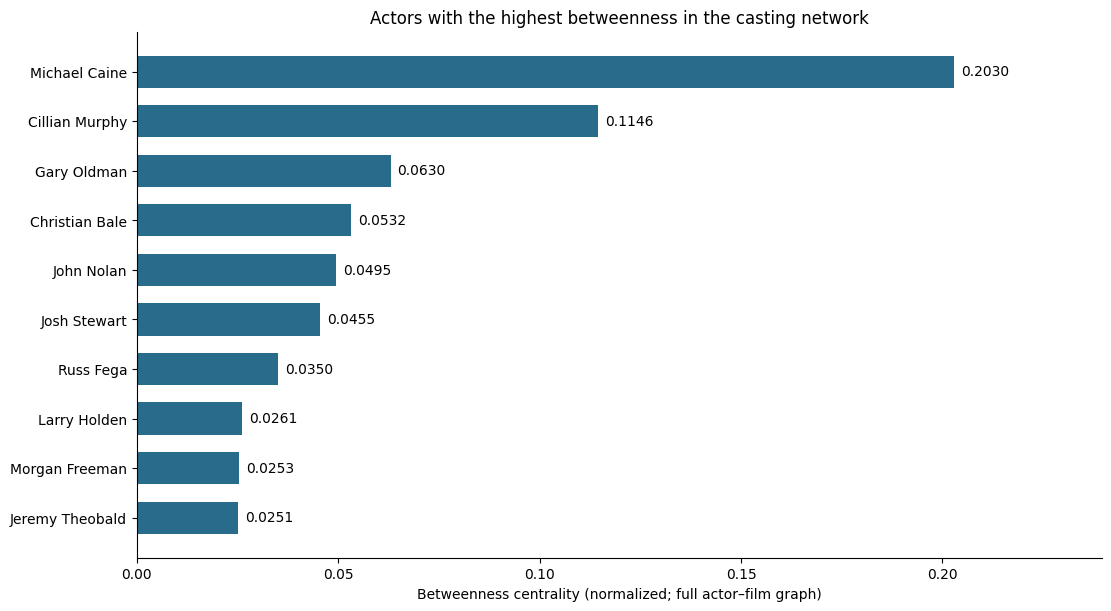

In [9]:
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
labels = [G.nodes[actor]["label"] for actor in top_connectors]
scores = [betweenness[actor] for actor in top_connectors]
bars = ax.barh(labels, scores, color=ACTOR_COLOR, height=0.65)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.4f", padding=5)
ax.set_xlim(0, max(scores) * 1.18)
ax.set(title="Actors with the highest betweenness in the casting network",
       xlabel="Betweenness centrality (normalized; full actor–film graph)")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIGURES / "nolan_actor_betweenness.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

## Film-to-film network: shared actors

We now project the **full** actor–film graph onto its film nodes. Each node is a
Nolan film. Two films are connected when at least one actor has a casting credit
in both. Each actor counts once per film pair, regardless of character or billing.
All films are retained, including any without a shared actor.

We store two measures for each edge, using the full source casts $C_i$ and $C_j$:

- **Shared actors:** $|C_i \cap C_j|$. This is also the default edge `weight`.
- **Jaccard overlap:** $|C_i \cap C_j| / |C_i \cup C_j|$.
  This accounts for cast size. For example, two casts of 10 actors sharing two
  actors have an overlap of $2 / 18 = 11.1\%$.

These are cast-overlap measures. They do not measure shared scenes or character
similarity. The cast inclusion rules are the same as in the full network above;
the recurring-actor filter does not change these calculations.

In [10]:
from itertools import combinations
import json

cast_sets = {film: set(G.neighbors(film)) for film in films}
film_projection = nx.Graph(
    name="Nolan film network: shared actors",
    source_graph=GRAPH_FILE.name,
    weight_definition="Number of distinct actors credited in both films",
    jaccard_definition="Shared actors divided by distinct actors in either cast",
)
film_projection.add_nodes_from(
    (film, {**G.nodes[film], "cast_size": len(cast_sets[film])})
    for film in films
)

for film_a, film_b in combinations(films, 2):
    shared = cast_sets[film_a] & cast_sets[film_b]
    if not shared:
        continue
    shared_ids = sorted(shared, key=lambda actor: G.nodes[actor]["label"])
    film_projection.add_edge(
        film_a, film_b,
        weight=len(shared),
        shared_actor_count=len(shared),
        jaccard=len(shared) / len(cast_sets[film_a] | cast_sets[film_b]),
        shared_actor_ids=json.dumps(shared_ids),
        shared_actor_names=json.dumps([G.nodes[actor]["label"] for actor in shared_ids]),
    )

# Check the raw counts against NetworkX's standard bipartite projection.
reference = nx.algorithms.bipartite.weighted_projected_graph(G, films)
assert set(film_projection) == set(films)
assert film_projection.number_of_edges() == reference.number_of_edges()
assert all(d["weight"] == reference[a][b]["weight"]
           for a, b, d in film_projection.edges(data=True))
assert nx.number_of_selfloops(film_projection) == 0

projection_file = GRAPH_FILE.parent / "nolan_film_projection.graphml"
nx.write_graphml(film_projection, projection_file)
print(f"Film nodes: {film_projection.number_of_nodes()}")
print(f"Film pairs sharing actors: {film_projection.number_of_edges()}")
print(f"Connected components: {nx.number_connected_components(film_projection)}")
print(f"Saved: {projection_file.name}")

Film nodes: 13
Film pairs sharing actors: 55
Connected components: 1
Saved: nolan_film_projection.graphml


### Compare shared counts and cast overlap

Both panels show **all links** and use the same circular layout, with films in
release-year order counterclockwise from the right. Node positions are fixed for
comparison. The legend in each panel gives its own line-width scale; the two
panels use different units. Node size is constant.

The Jaccard panel uses all actors in each cast as its denominator, including
actors who appear in only one Nolan film.

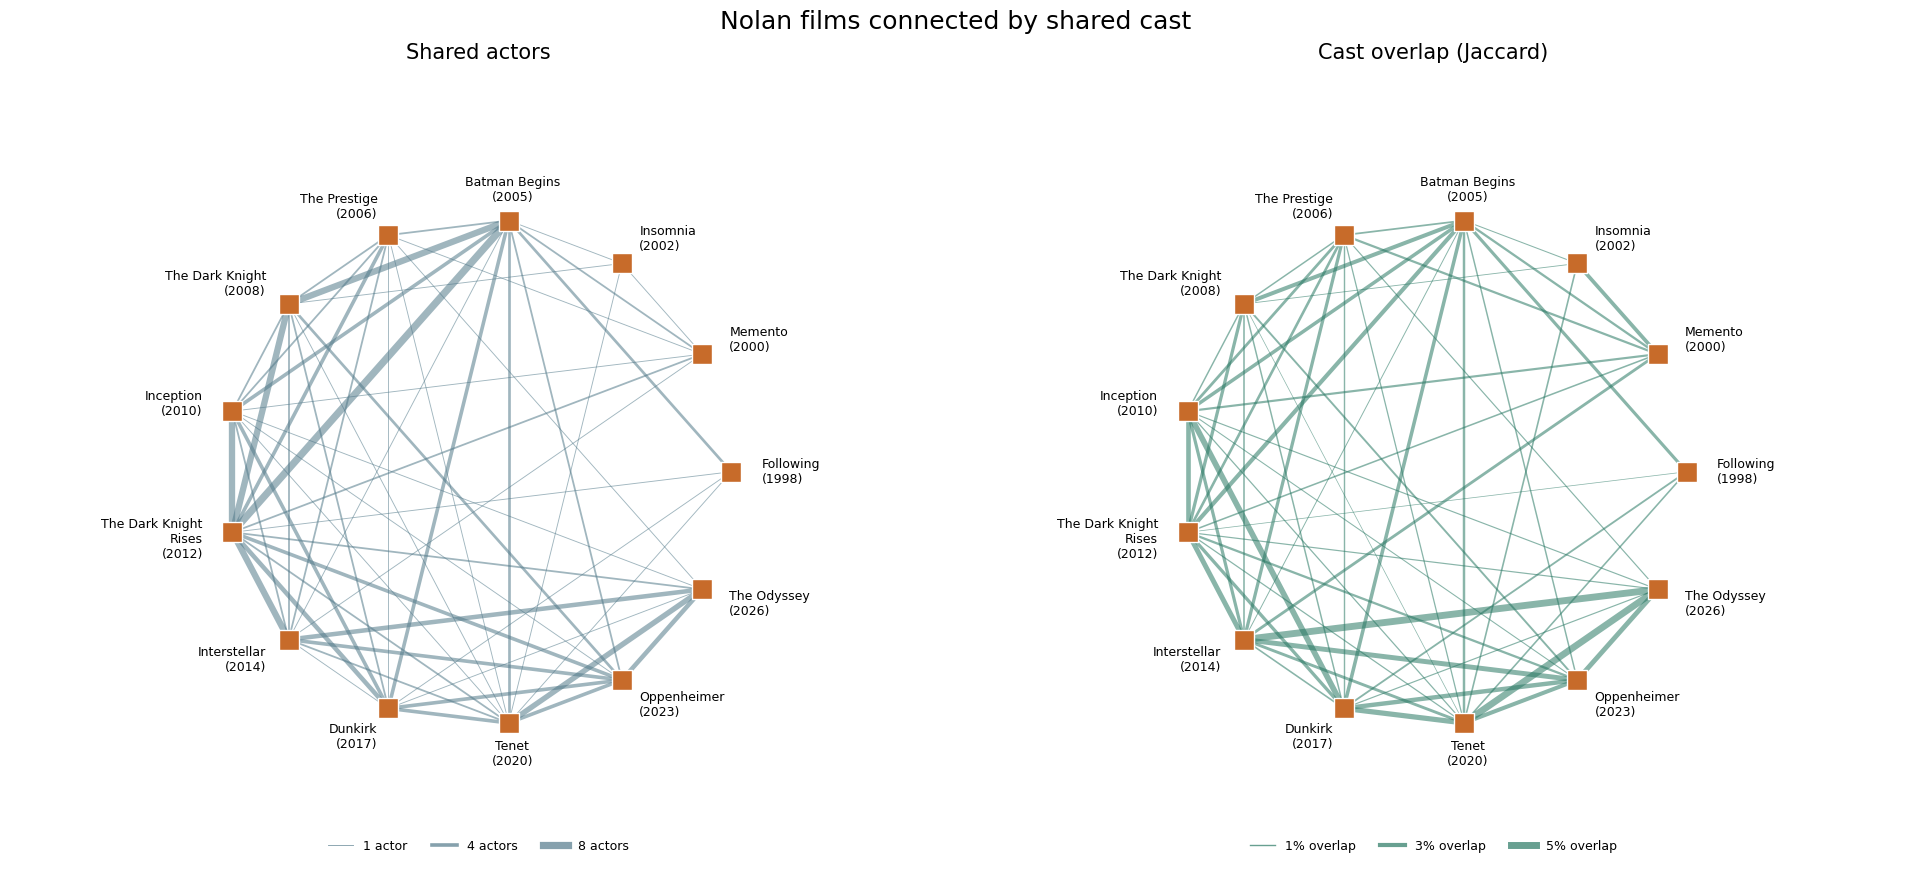

In [ ]:
positions = nx.circular_layout(films)
fig, axes = plt.subplots(1, 2, figsize=(19, 9), layout="constrained")
panels = [
    (axes[0], "shared_actor_count", "Shared actors", "#537a8a", 0.65,
     [(1, "1 actor"), (4, "4 actors"), (8, "8 actors")]),
    (axes[1], "jaccard", "Cast overlap (Jaccard)", "#287863", 100,
     [(0.01, "1% overlap"), (0.03, "3% overlap"), (0.05, "5% overlap")]),
]

for ax, measure, title, color, width_scale, examples in panels:
    edges = sorted(film_projection.edges(), key=lambda e: film_projection.edges[e][measure])
    nx.draw_networkx_edges(
        film_projection, positions, edgelist=edges, ax=ax,
        width=[width_scale * film_projection.edges[e][measure] for e in edges],
        edge_color=color, alpha=0.55,
    )
    nx.draw_networkx_nodes(
        film_projection, positions, ax=ax, node_shape="s", node_size=200,
        node_color=FILM_COLOR, edgecolors="white", linewidths=1,
    )
    for film in films:
        x, y = positions[film]
        label = textwrap.fill(G.nodes[film]["label"], width=19)
        label += f"\n({G.nodes[film]['year']})"
        ax.annotate(
            label, xy=(x, y), xytext=(22 * x, 22 * y),
            textcoords="offset points",
            ha="left" if x > 0.2 else "right" if x < -0.2 else "center",
            va="center", fontsize=9,
        )

    handles = [Line2D([], [], color=color, alpha=0.7,
                      linewidth=width_scale * value, label=label)
               for value, label in examples]
    ax.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
              handlelength=2, fontsize=9)
    ax.set_title(title, fontsize=15, pad=15)
    ax.set_xlim(-1.85, 1.85)
    ax.set_ylim(-1.55, 1.55)
    ax.set_aspect("equal")
    ax.set_axis_off()

fig.suptitle("Nolan films connected by shared cast", fontsize=18)
fig.savefig(FIGURES / "nolan_film_projection.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()

In [12]:
pair_rows = [
    {
        "film_a": G.nodes[a]["label"],
        "film_b": G.nodes[b]["label"],
        "shared": d["shared_actor_count"],
        "jaccard": d["jaccard"],
    }
    for a, b, d in film_projection.edges(data=True)
]

for measure, title in [
    ("shared", "Pairs with the most shared actors"),
    ("jaccard", "Pairs with the largest cast overlap"),
]:
    ranked = sorted(pair_rows, key=lambda row: (-row[measure], row["film_a"], row["film_b"]))[:10]
    table = [f"### {title}", "",
             "| Film A | Film B | Shared actors | Jaccard overlap |",
             "| :--- | :--- | ---: | ---: |"]
    table += [f"| {row['film_a']} | {row['film_b']} | {row['shared']} | {row['jaccard']:.2%} |"
              for row in ranked]
    display(Markdown("\n".join(table)))

### Pairs with the most shared actors

| Film A | Film B | Shared actors | Jaccard overlap |
| :--- | :--- | ---: | ---: |
| Batman Begins | The Dark Knight Rises | 8 | 2.99% |
| Batman Begins | The Dark Knight | 7 | 2.89% |
| Inception | The Dark Knight Rises | 7 | 3.32% |
| The Dark Knight | The Dark Knight Rises | 7 | 2.35% |
| The Dark Knight Rises | Interstellar | 7 | 3.57% |
| Tenet | The Odyssey | 6 | 4.84% |
| Interstellar | The Odyssey | 5 | 4.95% |
| Oppenheimer | The Odyssey | 5 | 3.47% |
| The Dark Knight Rises | Dunkirk | 5 | 2.37% |
| Batman Begins | Dunkirk | 4 | 2.56% |

### Pairs with the largest cast overlap

| Film A | Film B | Shared actors | Jaccard overlap |
| :--- | :--- | ---: | ---: |
| Interstellar | The Odyssey | 5 | 4.95% |
| Tenet | The Odyssey | 6 | 4.84% |
| Inception | Dunkirk | 4 | 4.08% |
| Dunkirk | Tenet | 4 | 3.74% |
| The Dark Knight Rises | Interstellar | 7 | 3.57% |
| Interstellar | Oppenheimer | 4 | 3.54% |
| Oppenheimer | The Odyssey | 5 | 3.47% |
| Inception | The Dark Knight Rises | 7 | 3.32% |
| Dunkirk | Oppenheimer | 4 | 3.17% |
| Batman Begins | The Dark Knight Rises | 8 | 2.99% |

### Inspect the actors behind a link

Change the two film titles below and rerun the cell to inspect another pair.
The cast sizes and actor names come from the same graph used in both panels.

In [13]:
film_a_title = "Batman Begins"
film_b_title = "The Dark Knight Rises"

film_by_title = {G.nodes[film]["label"]: film for film in films}
film_a, film_b = film_by_title[film_a_title], film_by_title[film_b_title]
shared = cast_sets[film_a] & cast_sets[film_b]
union = cast_sets[film_a] | cast_sets[film_b]
print(f"{film_a_title}: {len(cast_sets[film_a])} actors in the saved TMDB cast")
print(f"{film_b_title}: {len(cast_sets[film_b])} actors in the saved TMDB cast")
print(f"Shared actors: {len(shared)}")
print(f"Jaccard overlap: {len(shared) / len(union):.2%}")
print("\nShared cast:")
for actor in sorted(shared, key=lambda actor: G.nodes[actor]["label"]):
    print(f"- {G.nodes[actor]['label']}")

Batman Begins: 110 actors in the saved TMDB cast
The Dark Knight Rises: 166 actors in the saved TMDB cast
Shared actors: 8
Jaccard overlap: 2.99%

Shared cast:
- Christian Bale
- Cillian Murphy
- Gary Oldman
- Gus Lewis
- John Nolan
- Liam Neeson
- Michael Caine
- Morgan Freeman


The notebook saves its plots in `Final project/figures/` and the film projection
in `data/nolan/graphs/nolan_film_projection.graphml`. The saved projection includes
both edge measures and the identities of shared actors. Its default `weight`
attribute is the shared-actor count; select `jaccard` when analysing normalized
overlap.

These views show casting relationships. Testing whether Nolan casts actors in
their typical roles will also require the earlier-film extension and the later
text analysis.